# 02 — Churn propensity

> **Data sources:** Cell2Cell telecom churn (`jpacse/datasets-for-churn-telecom`, Kaggle mirror of the Teradata/Duke data) and the Hillstrom MineThatData e-mail experiment (minethatdata.com). **Downloaded:** 2026-08-10. Run `make data` to reproduce `data/raw/`.

A LightGBM churn classifier; discrimination via the shared riskkit metrics.

In [1]:
import pandas as pd

from churn_uplift.data import (
    CHURN_TARGET,
    cell2cell_xy,
    load_cell2cell,
    stratified_split,
)
from churn_uplift.evaluation import metric_summary, plots
from churn_uplift.models import churn_proba, train_propensity

train, test = stratified_split(load_cell2cell(), stratify_cols=[CHURN_TARGET])
X_train, y_train = cell2cell_xy(train)
X_test, y_test = cell2cell_xy(test)
model = train_propensity(X_train, y_train)
p_test = churn_proba(model, X_test)
pd.Series(metric_summary(y_test, p_test)).round(4)

auc     0.6748
gini    0.3495
ks      0.2551
dtype: float64

## ROC

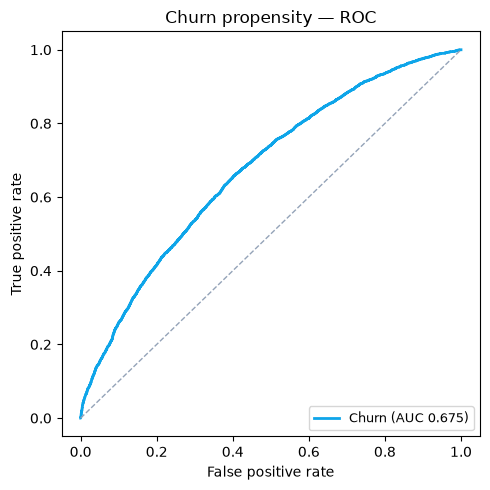

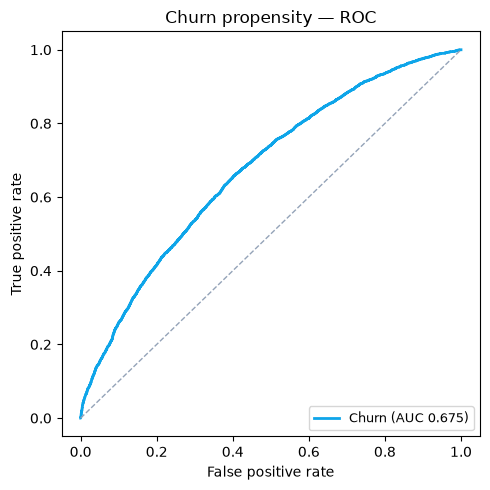

In [2]:
plots.plot_propensity_roc(y_test, p_test)

## Highest-risk customers

The ranking a retention team acts on: the top-scored customers by churn probability.

In [3]:
test.assign(p_churn=p_test.values).nlargest(5, "p_churn")[
    ["MonthsInService", "MonthlyRevenue", "CustomerCareCalls", "p_churn"]
]

,MonthsInService,MonthlyRevenue,CustomerCareCalls,p_churn
5107,11,0.00,0.0,0.911217
2645,14,26.42,0.0,0.905226
3286,13,5.00,0.0,0.902711
3224,11,10.00,0.0,0.891910
1899,13,53.99,0.0,0.889015
